### Target Distributions & Energy Intensity

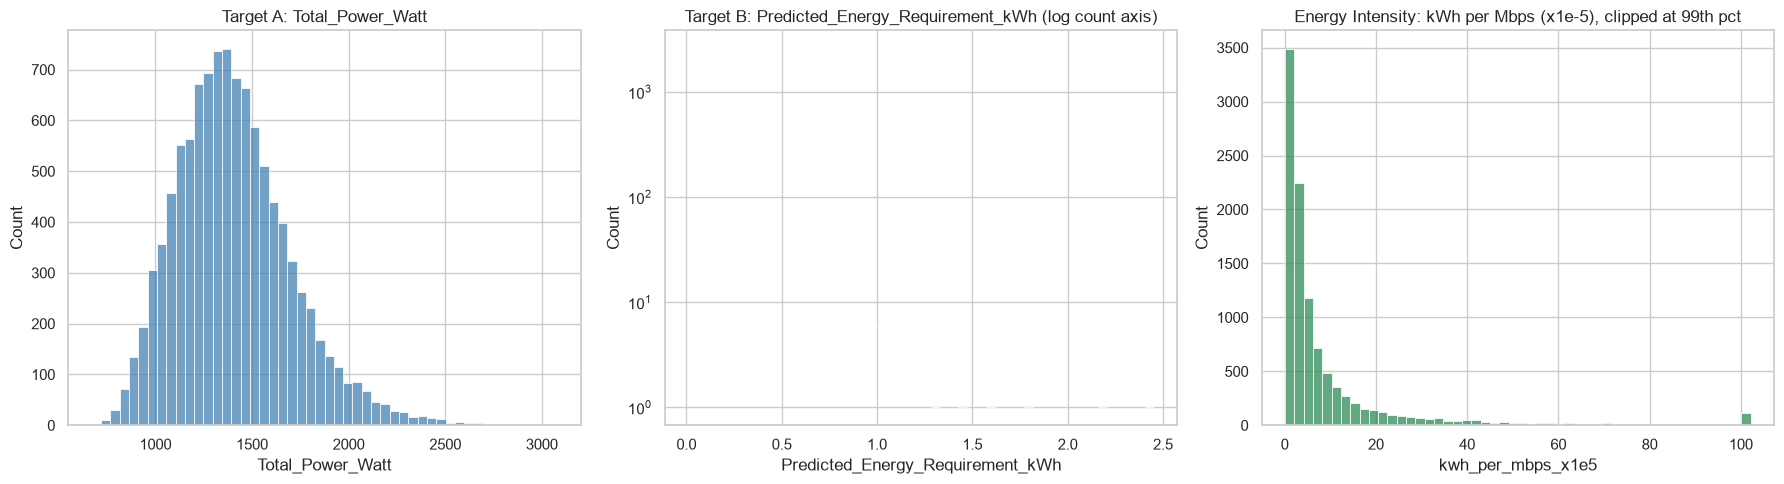

                                    count      mean      std      min  \
Total_Power_Watt                  10500.0  1405.116  298.238  669.690   
Predicted_Energy_Requirement_kWh  10500.0     0.162    0.151    0.010   
kwh_per_mbps_x1e5                 10500.0    10.232   21.796    0.061   

                                       25%       50%       75%       max  
Total_Power_Watt                  1196.125  1373.890  1578.810  3080.390  
Predicted_Energy_Requirement_kWh     0.068     0.119     0.201     2.453  
kwh_per_mbps_x1e5                    1.586     3.569     9.253   496.308  


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
sns.set_theme(style="whitegrid")

df = pd.read_csv('../data/prepared_energy_dataset.csv')
tr = df[df['split'] == 'train'].copy()
tr['kwh_per_mbps_x1e5'] = (tr['Predicted_Energy_Requirement_kWh'] / tr['Traffic_Volume_Mbps']) * 1e5
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(tr['Total_Power_Watt'], bins=50, ax=ax[0], color='steelblue')
ax[0].set_title('Target A: Total_Power_Watt')
sns.histplot(tr['Predicted_Energy_Requirement_kWh'], bins=50, ax=ax[1], color='darkorange', log_scale=(False, True))
ax[1].set_title('Target B: Predicted_Energy_Requirement_kWh (log count axis)')

intensity_clip = tr['kwh_per_mbps_x1e5'].clip(upper=tr['kwh_per_mbps_x1e5'].quantile(.99))
sns.histplot(intensity_clip, bins=50, ax=ax[2], color='seagreen')
ax[2].set_title('Energy Intensity: kWh per Mbps (x1e-5), clipped at 99th pct')

plt.tight_layout()
plt.show()

print(tr[['Total_Power_Watt', 'Predicted_Energy_Requirement_kWh', 'kwh_per_mbps_x1e5']].describe().T.round(3))

### Temporal Analysis (Weekday vs. Weekend)

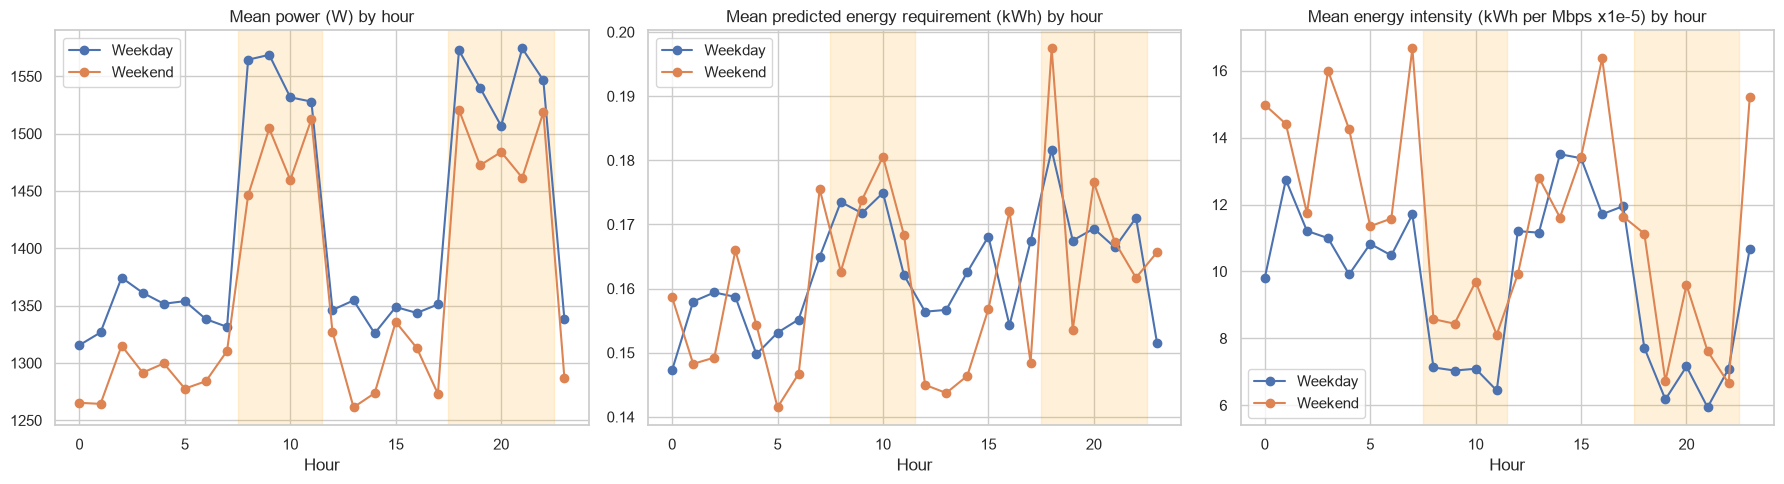

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ('Total_Power_Watt', 'Mean power (W) by hour', 0),
    ('Predicted_Energy_Requirement_kWh', 'Mean predicted energy requirement (kWh) by hour', 1),
    ('kwh_per_mbps_x1e5', 'Mean energy intensity (kWh per Mbps x1e-5) by hour', 2)
]

for col, title, idx in metrics:
    h_data = tr.groupby(['Hour', 'Is_Weekend'])[col].mean().unstack()
    h_data.columns = ['Weekday', 'Weekend']
    
    h_data.plot(ax=ax[idx], marker='o')
    ax[idx].axvspan(7.5, 11.5, color='orange', alpha=0.15) 
    ax[idx].axvspan(17.5, 22.5, color='orange', alpha=0.15)
    ax[idx].set_title(title)
    ax[idx].set_xticks(range(0, 24, 5))

plt.tight_layout()
plt.show()

### Infrastructure and Categorical Drivers

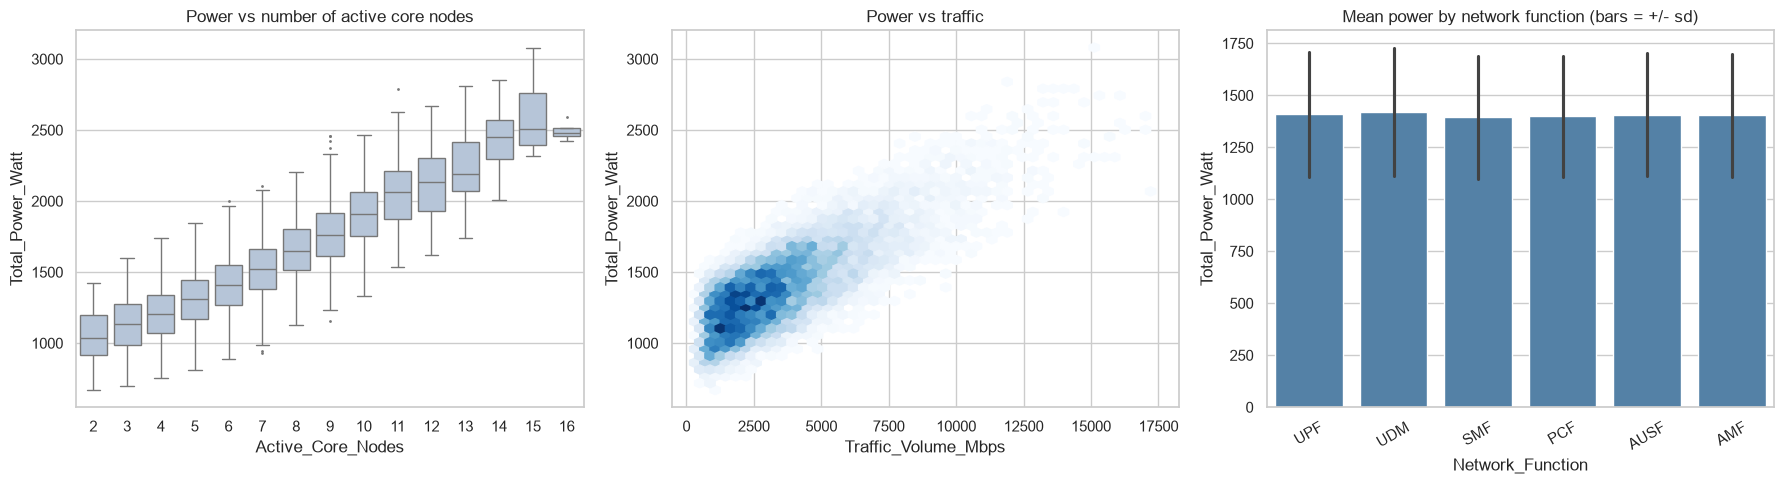

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=tr, x='Active_Core_Nodes', y='Total_Power_Watt', ax=ax[0], color='lightsteelblue', fliersize=1)
ax[0].set_title('Power vs number of active core nodes')
ax[1].hexbin(tr['Traffic_Volume_Mbps'], tr['Total_Power_Watt'], gridsize=45, cmap='Blues', mincnt=1)
ax[1].set_title('Power vs traffic')
ax[1].set_xlabel('Traffic_Volume_Mbps')
ax[1].set_ylabel('Total_Power_Watt')

sns.barplot(data=tr, x='Network_Function', y='Total_Power_Watt', ax=ax[2], color='steelblue', errorbar='sd')
ax[2].set_title('Mean power by network function (bars = +/- sd)')
ax[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Autocorrelation (Time-Series Dependency)

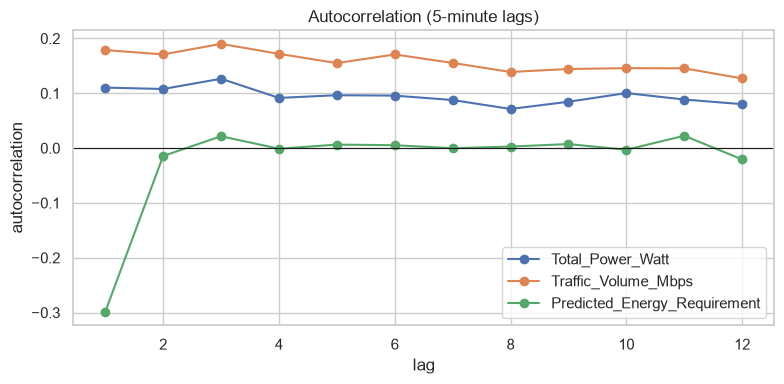

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
lags = range(1, 13)

for col, lab in [('Total_Power_Watt', 'Total_Power_Watt'), 
                 ('Traffic_Volume_Mbps', 'Traffic_Volume_Mbps'), 
                 ('Predicted_Energy_Requirement_kWh', 'Predicted_Energy_Requirement')]:
    
    autocorrelations = [tr[col].autocorr(l) for l in lags]
    ax.plot(lags, autocorrelations, marker='o', label=lab)

ax.axhline(0, color='k', lw=0.8)
ax.set_title('Autocorrelation (5-minute lags)')
ax.set_xlabel('lag')
ax.set_ylabel('autocorrelation')
ax.legend()

plt.tight_layout()
plt.show()